# Train a Style LoRA (Anime / Cartoon / Digital Art) on Google Colab

Trains a **Stable Diffusion 1.5 LoRA** on your own images using a free T4 GPU.

**Before you start**
1. Runtime > Change runtime type > **T4 GPU**
2. Put your training images (use only images you own or have rights to) in Google Drive at
   `MyDrive/lora_<STYLE_NAME>/raw` (the folder is created for you in step 3).
3. Train **one style per run** (anime, cartoon, or digital art). Run the notebook again with a new `STYLE_NAME` for the next style.

Aim for 100-500 clean, consistent images. Run cells top to bottom.

## 1. Check GPU

In [ ]:
!nvidia-smi

Tue Oct 27 04:37:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies

In [ ]:
!pip install -q diffusers==0.31.0 accelerate peft datasets imagehash gradio
!wget -q https://raw.githubusercontent.com/huggingface/diffusers/v0.31.0/examples/text_to_image/train_text_to_image_lora.py -O train_lora.py
print("done")

done


## 3. Settings and Google Drive

Change `STYLE_NAME` and `TRIGGER` for each style. After this cell runs, upload your images into the `raw` folder in Drive, then continue.

In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

# ---- settings you can change ----
STYLE_NAME = "anime"            # anime / cartoon / digital_art
TRIGGER    = "anime_style"      # word you will put in prompts to activate the style
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
RESOLUTION = 512
MAX_STEPS  = 1500               # ~1500 for 100-300 images, ~2500 for 500+
RANK       = 16                 # LoRA size/capacity (8-32)
LR         = 1e-4
# ----------------------------------

ROOT    = f"/content/drive/MyDrive/lora_{STYLE_NAME}"
RAW_DIR = f"{ROOT}/raw"
OUT_DIR = f"{ROOT}/output"
WORK    = "/content/dataset/train"
for d in (RAW_DIR, OUT_DIR, WORK):
    os.makedirs(d, exist_ok=True)
print("Upload your images to:", RAW_DIR)
print("Images found:", len([f for f in os.listdir(RAW_DIR) if f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))]))

Mounted at /content/drive
Upload your images to: /content/drive/MyDrive/lora_anime/raw
Images found: 0


In [ ]:
from datasets import load_dataset
DATASET = "neonforestmist/GPT_Storybook_Anime_Style_Images"
ds = load_dataset(DATASET, split="train", streaming=True)
first = next(iter(ds))
print(list(first.keys()))
col = next((k for k, v in first.items() if hasattr(v, "convert")), None)
assert col, "this dataset has no image column, pick another"
n = 0
for row in ds:
    row[col].convert("RGB").save(f"{RAW_DIR}/hf_{n:04d}.png")
    n += 1
    if n == 300: break
print("saved", n, "from column", col)

README.md:   0%|          | 0.00/3.61k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2049 [00:00<?, ?it/s]

['image', 'text']
saved 300 from column image


## 4. Prepare images (convert, resize, crop, remove duplicates)

In [ ]:
import glob, imagehash
from PIL import Image

files = [f for f in glob.glob(f"{RAW_DIR}/**/*", recursive=True)
         if f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))]

seen, kept, skipped = set(), 0, 0
for f in sorted(files):
    try:
        img = Image.open(f).convert("RGB")
    except Exception:
        skipped += 1
        continue
    if min(img.size) < 384:           # too small, would look blurry
        skipped += 1
        continue
    h = str(imagehash.phash(img))
    if h in seen:                     # duplicate
        skipped += 1
        continue
    seen.add(h)
    w, hgt = img.size
    scale = RESOLUTION / min(w, hgt)
    img = img.resize((round(w * scale), round(hgt * scale)), Image.LANCZOS)
    w, hgt = img.size
    left, top = (w - RESOLUTION) // 2, (hgt - RESOLUTION) // 2
    img = img.crop((left, top, left + RESOLUTION, top + RESOLUTION))
    img.save(f"{WORK}/{kept:04d}.jpg", quality=95)
    kept += 1

print(f"Kept {kept} images, skipped {skipped} (too small, duplicate, or unreadable)")
assert kept >= 20, "Add more images: use at least 20, ideally 100+"

Kept 300 images, skipped 0 (too small, duplicate, or unreadable)


## 5. Auto-caption images

BLIP writes a short description of each image, and your trigger word is added at the start. Open `metadata.jsonl` afterwards and fix any bad captions if you want better results.

In [ ]:
import json, torch
from transformers import BlipProcessor, BlipForConditionalGeneration

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base", torch_dtype=torch.float16).to("cuda")

names = sorted(f for f in os.listdir(WORK) if f.endswith(".jpg"))
with open(f"{WORK}/metadata.jsonl", "w") as out:
    for i, name in enumerate(names):
        img = Image.open(f"{WORK}/{name}")
        inputs = processor(img, return_tensors="pt").to("cuda", torch.float16)
        ids = blip.generate(**inputs, max_new_tokens=40)
        text = processor.decode(ids[0], skip_special_tokens=True).strip()
        out.write(json.dumps({"file_name": name, "text": f"{TRIGGER}, {text}"}) + "\n")
        if i < 5:
            print(name, "->", f"{TRIGGER}, {text}")

del blip, processor
torch.cuda.empty_cache()
print(f"Captioned {len(names)} images")

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

0000.jpg -> anime_style, the legend of zealod
0001.jpg -> anime_style, a boy holding a yellow balloon in front of a pier
0002.jpg -> anime_style, two people standing on a hill looking at the sky
0003.jpg -> anime_style, a girl stands in front of a doorway with a rain
0004.jpg -> anime_style, a girl playing an accordion in the park
Captioned 300 images


In [ ]:
!pip install -q -U diffusers
from importlib.metadata import version
v = version("diffusers"); print("diffusers", v)
!wget -q https://raw.githubusercontent.com/huggingface/diffusers/v{v}/examples/text_to_image/train_text_to_image_lora.py -O train_lora.py || wget -q https://raw.githubusercontent.com/huggingface/diffusers/main/examples/text_to_image/train_text_to_image_lora.py -O train_lora.py
!ls -l train_lora.py

diffusers 0.42.0
-rw-r--r-- 1 root root 43229 Oct 27 05:10 train_lora.py


In [ ]:
!pip uninstall -y -q torchao

## 6. Train the LoRA (about 1-2 hours on a free T4)

In [ ]:
!accelerate launch --mixed_precision=fp16 train_lora.py --mixed_precision=fp16 \
  --pretrained_model_name_or_path={BASE_MODEL} \
  --train_data_dir={WORK} \
  --image_column=image --caption_column=text \
  --resolution={RESOLUTION} --center_crop --random_flip \
  --train_batch_size=1 --gradient_accumulation_steps=4 \
  --gradient_checkpointing \
  --max_train_steps={MAX_STEPS} \
  --learning_rate={LR} --lr_scheduler=cosine --lr_warmup_steps=100 \
  --rank={RANK} \
  --checkpointing_steps=500 \
  --dataloader_num_workers=2 \
  --seed=42 \
  --output_dir={OUT_DIR}

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_processes` was set to a value of `1`
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
10/27/2026 05:17:47 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
10/27/2026 05:17:47 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
10/27/2026 

## 7. Test your LoRA

Always include your trigger word in the prompt. Try a few prompts; if results look washed out, the LoRA is undertrained, and if every image looks like a training image, it is overtrained (lower `MAX_STEPS`).

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/28 [00:00<?, ?it/s]

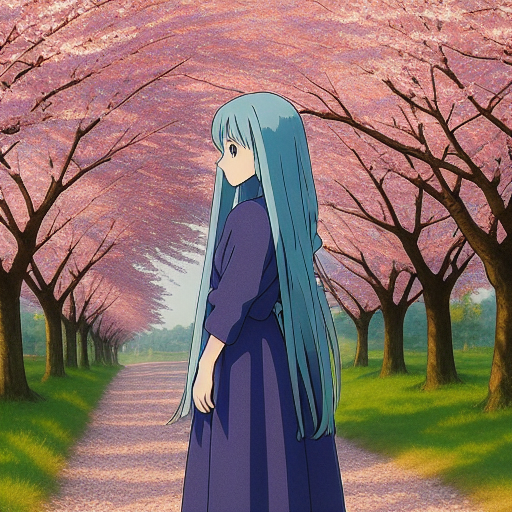

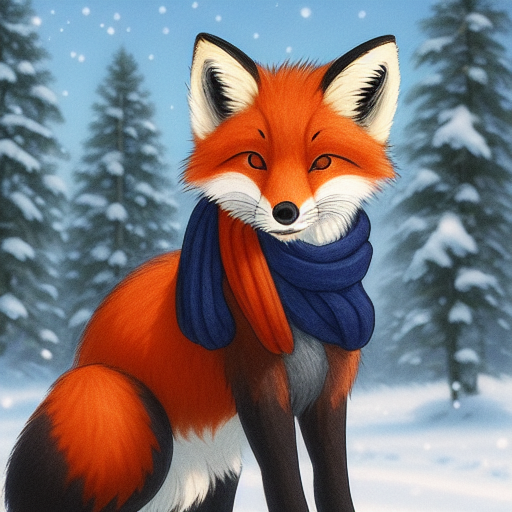

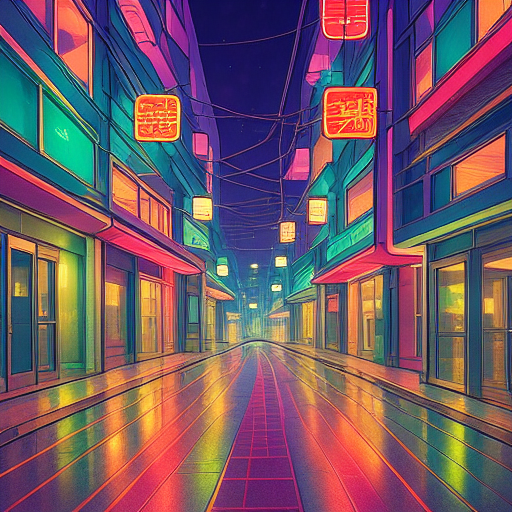

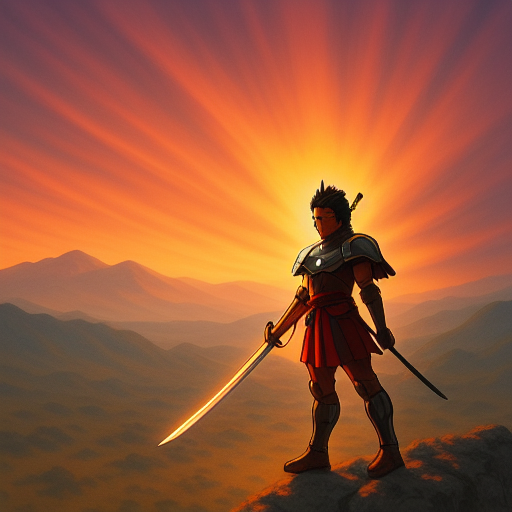

In [ ]:
import torch
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

pipe = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda")
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.load_lora_weights(OUT_DIR)

prompts = [
    f"{TRIGGER}, a girl with long blue hair standing in a cherry blossom garden",
    f"{TRIGGER}, a cute fox wearing a scarf in a snowy forest",
    f"{TRIGGER}, a futuristic city street at night with neon lights",
    f"{TRIGGER}, a warrior holding a glowing sword on a cliff at sunset",
]
neg = "lowres, bad anatomy, bad hands, blurry, text, watermark, extra fingers"

images = pipe(prompts, negative_prompt=[neg] * len(prompts),
              num_inference_steps=28, guidance_scale=7.5,
              generator=torch.Generator("cuda").manual_seed(1)).images

from IPython.display import display
for im in images:
    display(im)

  0%|          | 0/40 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/13 [00:00<?, ?it/s]

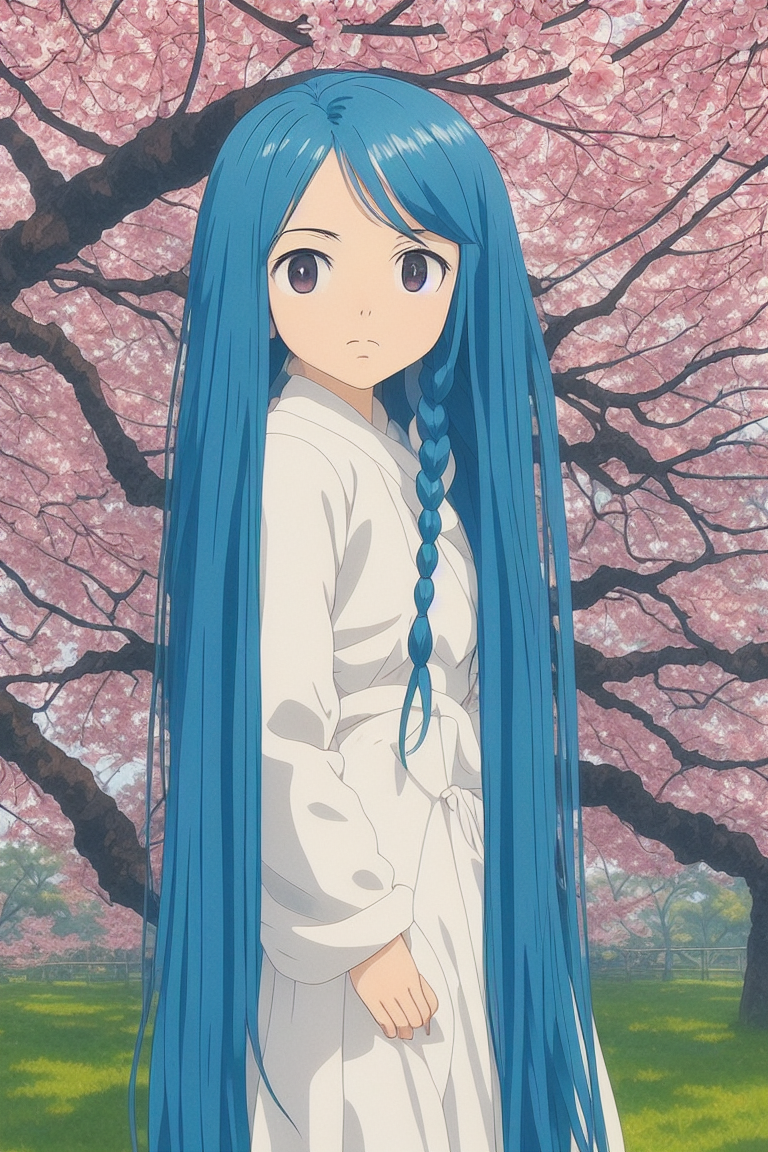

In [ ]:
from diffusers import StableDiffusionImg2ImgPipeline
prompt = f"{TRIGGER}, masterpiece, best quality, highly detailed, intricate details, sharp focus, a girl with long blue hair in a cherry blossom garden"
neg = "lowres, blurry, bad anatomy, bad hands, extra fingers, deformed, jpeg artifacts, text, watermark"
g = torch.Generator("cuda").manual_seed(7)
kw = dict(negative_prompt=neg, guidance_scale=7, cross_attention_kwargs={"scale": 0.9}, generator=g)

base = pipe(prompt, width=512, height=768, num_inference_steps=40, **kw).images[0]
up = StableDiffusionImg2ImgPipeline.from_pipe(pipe)
final = up(prompt, image=base.resize((768, 1152)), strength=0.45, num_inference_steps=30, **kw).images[0]
final

## 8. Simple web app (optional)

Launches a Gradio page with a public link so you can generate images from your browser.

In [ ]:
import gradio as gr

def generate(prompt, negative, steps, cfg, seed):
    gen = torch.Generator("cuda").manual_seed(int(seed))
    full = prompt if TRIGGER in prompt else f"{TRIGGER}, {prompt}"
    return pipe(full, negative_prompt=negative, num_inference_steps=int(steps),
                guidance_scale=cfg, generator=gen).images[0]

gr.Interface(
    fn=generate,
    inputs=[gr.Textbox(label="Prompt"),
            gr.Textbox(value=neg, label="Negative prompt"),
            gr.Slider(10, 50, value=28, step=1, label="Steps"),
            gr.Slider(1, 15, value=7.5, label="Guidance"),
            gr.Number(value=1, label="Seed")],
    outputs=gr.Image(),
    title=f"{STYLE_NAME} generator",
).launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9d19af67fc41114a7e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os
print(os.listdir(OUT_DIR))   # pytorch_lora_weights.safetensors තියෙනවද බලන්න
from google.colab import files
files.download(f"{OUT_DIR}/pytorch_lora_weights.safetensors")

['logs', 'checkpoint-500', 'checkpoint-1000', 'checkpoint-1500', 'pytorch_lora_weights.safetensors']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>